# Customize plots and export results

In [1]:
%matplotlib inline

# Import plotting, export-reading, and analysis tools.
from pathlib import Path
import json
import tempfile
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


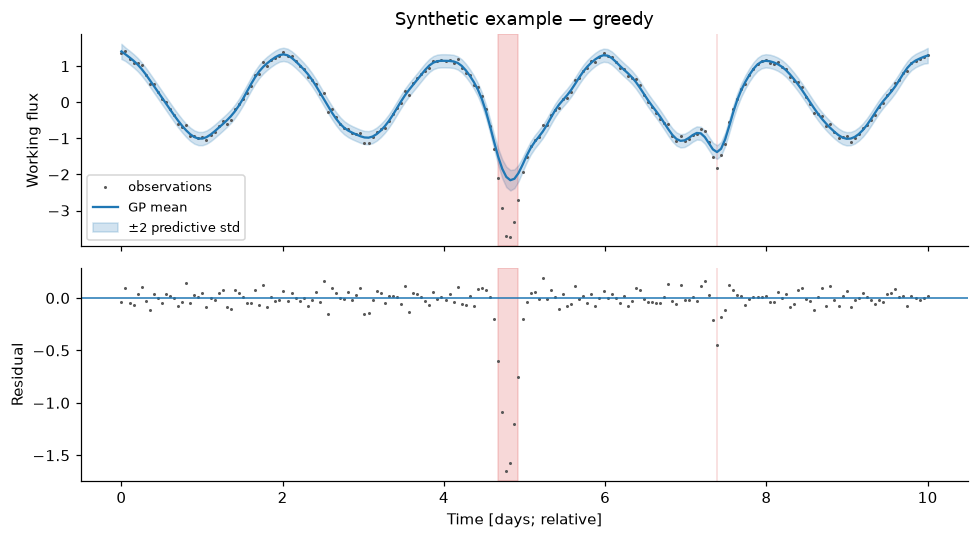

In [2]:
# Generate reproducible observations and inject two known dips.
lc = Nahiku.from_synthetic_noise(duration=10, n_points=200, period=2,
                                 amplitude=0.3, white_noise=0.02, red_noise=0, seed=48)
lc.inject_anomaly(center=4.8, width=0.12, depth=0.8, shape="gaussian")
lc.inject_anomaly(center=7.4, width=0.07, depth=0.45, shape="exocomet")
# Standardize and fit the shared GP before running independent searches.
lc.standardize()
lc.fit_gp(period=2, length_scale=4, iterations=120)
# Use leave-one-out seeds for greedy and a candidate grid for exhaustive search.
greedy = lc.greedy_search(sigma=4, grow_sigma=2, seed_statistic="loo", growth="threshold",
                               direction="negative", gap_factor=5, max_events=20, backend="numpy")
exhaustive = lc.exhaustive_search(min_points=3, max_points=16, step=3,
                                size_step=3, threshold=1e-8)

# Customize the returned Matplotlib axes without changing the numerical result.
fig, axes = greedy.plot()
axes[0].set_title("Synthetic example — greedy");

The upper panel shows the GP prediction conditioned on observations outside all detected intervals. In the lower panel, each colored curve excludes only its own candidate window. Matching dots identify the excluded observations, and bands show ±2 predictive observation standard deviations. By default, each merged event is represented by its strongest selected candidate, with ties resolved by sample bounds. Use `selection="all"` to show all selected windows, including overlaps. A merged event may span several scored windows. Joint scores use correlations between observations as well as the pointwise uncertainties shown in the bands.

`event_index` selects a merged event by its zero-based index and plots its representative candidate's GP across the full light curve. Other detections remain in the conditioning data. The stored predictions include any candidate-specific refits, so plotting requires no further optimization or live GP. Use `kind="residuals"` to inspect residuals after excluding all detected intervals. Numerical exports include the conditional distributions.

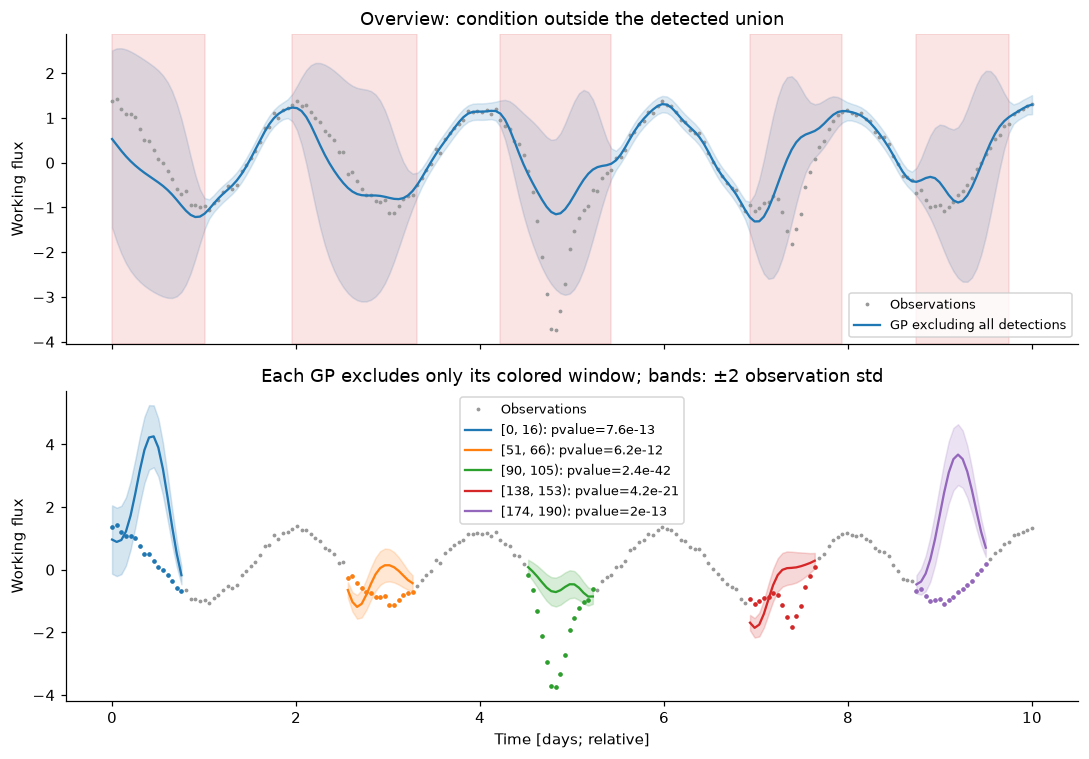

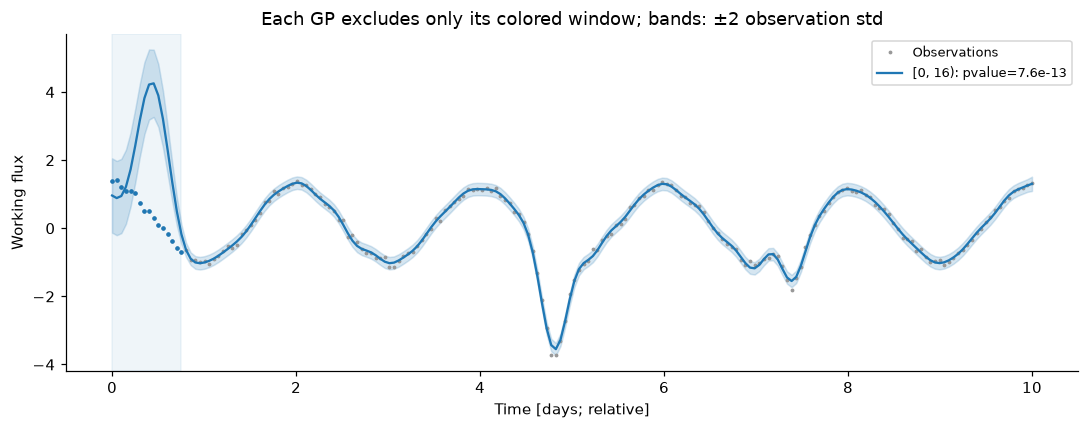

In [3]:
# Inspect the scored conditional fit for one representative window per event.
exhaustive.plot(kind="conditional");

# Plot one candidate's GP over the full light curve, excluding only that window.
if exhaustive.intervals:
    exhaustive.plot(kind="conditional", event_index=0);

# All overlapping selected windows remain accessible with selection="all".
# exhaustive.plot(kind="conditional", selection="all");

In [4]:
# Use a temporary directory for this demonstration; choose a persistent path to keep files.
with tempfile.TemporaryDirectory() as directory:
    # Export each independent result under a distinct filename prefix.
    greedy_paths = greedy.export(Path(directory) / "greedy")
    paths = exhaustive.export(Path(directory) / "exhaustive")
    print("Export types:", sorted(paths))

    # Read numerical arrays without pickle and verify the detection mask.
    with np.load(paths["arrays"], allow_pickle=False) as arrays:
        assert np.array_equal(arrays["mask"], exhaustive.mask)

        # Match the first saved conditional distribution to its bounds and score.
        metadata = json.loads(paths["metadata"].read_text())
        records = metadata["conditional_predictions"]
        print("Saved selected windows:", len(records))
        if records:
            record = records[0]
            key = f"conditional_{record['index']}_full_mean"
            assert np.array_equal(
                arrays[key], exhaustive.conditional_predictions[0]["full_mean"],
            )
            print("First saved window:", record["start"], record["stop"])
            print("Full-grid prediction shape:", arrays[key].shape)

# Temporary files are cleaned up when the context exits; the results stay in memory.

Export types: ['arrays', 'candidates', 'metadata', 'samples']
Saved selected windows: 41
First saved window: 90 105
Full-grid prediction shape: (200,)


## Interpret the result

Plot methods return Matplotlib figures and axes, so titles, labels, limits, and saved figure formats can be customized without changing the analysis. Greedy results default to a fit-and-residual view. Exhaustive results default to an overview plus representative held-out predictions; `event_index` shows one representative GP across the entire light curve. Colored dots identify its excluded observations. These stored predictions remain available after the original light-curve object changes.

The exhaustive example selects overlapping candidate windows that merge into events. The JSON records and NPZ arrays retain every selected window, rather than only the plotted representatives. Each JSON index identifies NPZ keys such as `conditional_0_mean`, `conditional_0_std`, `conditional_0_covariance`, `conditional_0_full_mean`, and `conditional_0_full_std`. Interval arrays describe the scored window; full-grid arrays span all observation timestamps. Standard deviations include observation noise.

`SearchResult.export` writes numerical arrays (NPZ), sample and candidate tables (CSV), and settings and provenance (JSON). The candidate CSV includes every tested exhaustive window, whereas conditional prediction arrays are saved for selected windows. The assertions verify that the exported mask and a full-grid prediction exactly match the in-memory result. Loading these files does not reconstruct a fitted Python model or a `SearchResult` automatically.

This demonstration uses a temporary directory, so its files are removed when the context exits. To retain exports, use a persistent prefix such as `Path("outputs") / "exhaustive"`. Exports are analysis snapshots; detection scores and event boundaries retain the interpretation limits discussed in the search tutorials.

Consult the API reference for parameter and return-value details.